# 07 · Réplica del paper 4 (El Alaoui et al., 2027)

Grupo 4 · Leishmaniosis cutánea en Cajamarca · Integrante: Franz Javier Vilcapoma Madueño

El paper 4 pronostica los casos mensuales de leishmaniosis cutánea en Errachidia (Marruecos) con un **SARIMA**
construido con el método de Box-Jenkins: pruebas de estacionariedad, cuadrícula de órdenes elegida por **AIC**,
prueba de **Ljung-Box** en los residuos y evaluación con **RMSE y MAE**. El orden elegido fue **SARIMA(0,1,0)(1,1,0)₁₂**.

Aquí se replica en `src/modelo_paper4.py` con dos variantes, una serie por distrito y solo casos (como el paper):

| Variante | Orden |
|---|---|
| `SARIMA_paper` | (0,1,0)(1,1,0)₁₂ del paper, en todos los distritos |
| `SARIMA_AIC` | menor AIC por distrito: p, q, P, Q ∈ {0,1}, d ∈ {0,1}, D = 1, s = 12 |

Se evalúa en las mismas filas que los demás modelos, con pronóstico a un paso (cada mes con los casos observados
hasta el mes anterior).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

import comparacion_final as cf
import modelo_paper4 as p4

pd.set_option("display.width", 200)

## 1. Entrenamiento

`RUN_EXPERIMENT = True` reajusta los SARIMA de los dos protocolos (≈1 min cada uno con 4 procesos) y regenera `results/paper4*/` y `results/comparacion_final/`. Por defecto solo se leen los resultados guardados.

In [2]:
RUN_EXPERIMENT = False

if RUN_EXPERIMENT:
    p4.main("oficial", ROOT / "results/paper4")
    p4.main("historico", ROOT / "results/paper4_historico")
    cf.main()

## 2. Órdenes elegidos por AIC y diagnóstico de Ljung-Box (protocolo oficial)

In [3]:
ordenes = pd.read_csv(ROOT / "results/paper4/ordenes_por_distrito.csv", dtype={"ubigeo": str})
print(f"Distritos: {len(ordenes)}")
print(f"Residuos como ruido blanco (Ljung-Box p > 0,05): {(ordenes.ljung_box_p > 0.05).mean():.0%}")
ordenes.orden_AIC.value_counts().rename("distritos").to_frame()

Distritos: 57
Residuos como ruido blanco (Ljung-Box p > 0,05): 86%


,distritos
orden_AIC,
"(1, 0, 1)x(0, 1, 1, 12)",22
"(0, 1, 1)x(0, 1, 1, 12)",13
"(0, 0, 1)x(0, 1, 1, 12)",9
"(1, 1, 1)x(0, 1, 1, 12)",7
"(0, 1, 1)x(1, 1, 1, 12)",2
"(1, 0, 1)x(1, 1, 1, 12)",2
"(1, 1, 1)x(1, 1, 1, 12)",1
"(0, 0, 0)x(0, 1, 1, 12)",1


## 3. Resultados del SARIMA

In [4]:
for protocolo in ("paper4", "paper4_historico"):
    m = pd.read_csv(ROOT / f"results/{protocolo}/metricas.csv")
    print(protocolo)
    display(m[["modelo", "orden", "RMSE_validacion", "RMSE", "MAE", "MASE", "alerta_PR_AUC",
               "alerta_recall", "alerta_precision", "alerta_false_alerts"]].round(3))

paper4


,modelo,orden,RMSE_validacion,RMSE,MAE,MASE,alerta_PR_AUC,alerta_recall,alerta_precision,alerta_false_alerts
0,SARIMA_paper,"(0,1,0)(1,1,0)12",1.516,1.246,0.669,0.650,0.141,0.417,0.088,518
1,SARIMA_AIC,menor AIC por distrito,1.158,0.946,0.556,0.541,0.083,0.550,0.057,1092


paper4_historico


,modelo,orden,RMSE_validacion,RMSE,MAE,MASE,alerta_PR_AUC,alerta_recall,alerta_precision,alerta_false_alerts
0,SARIMA_paper,"(0,1,0)(1,1,0)12",1.879,1.373,0.837,0.637,0.034,0.304,0.041,163
1,SARIMA_AIC,menor AIC por distrito,1.672,1.086,0.731,0.556,0.023,0.435,0.016,598


## 4. Comparación con los demás modelos, protocolo oficial (prueba 2019-2024)

In [5]:
oficial = pd.read_csv(ROOT / "results/comparacion_final/metricas_oficial.csv")
reg = ["origen", "modelo", "entradas", "RMSE_validacion", "RMSE", "MAE", "MASE"]
display(oficial.sort_values("RMSE")[reg].round(3).reset_index(drop=True))

,origen,modelo,entradas,RMSE_validacion,RMSE,MAE,MASE
0,Paper 2,DFNN,Casos (7) + clima,1.115,0.916,0.602,0.585
1,Paper 2,DFNN,Solo casos (7),1.115,0.916,0.602,0.585
2,Equipo,MLP,Solo casos (7),1.131,0.922,0.575,0.559
3,Equipo,MLP,Casos (7) + clima,1.131,0.922,0.575,0.559
4,Equipo,Random Forest,Solo casos (7),1.127,0.926,0.598,0.581
5,Equipo,Random Forest,Casos (7) + clima,1.127,0.926,0.598,0.581
6,Equipo,CNN temporal,Casos (7) + clima,1.128,0.938,0.621,0.604
7,Equipo,CNN temporal,Solo casos (7),1.128,0.938,0.621,0.604
8,Equipo,Ridge / logística,Casos (7) + clima,1.129,0.940,0.583,0.567
9,Equipo,Ridge / logística,Solo casos (7),1.129,0.940,0.583,0.567


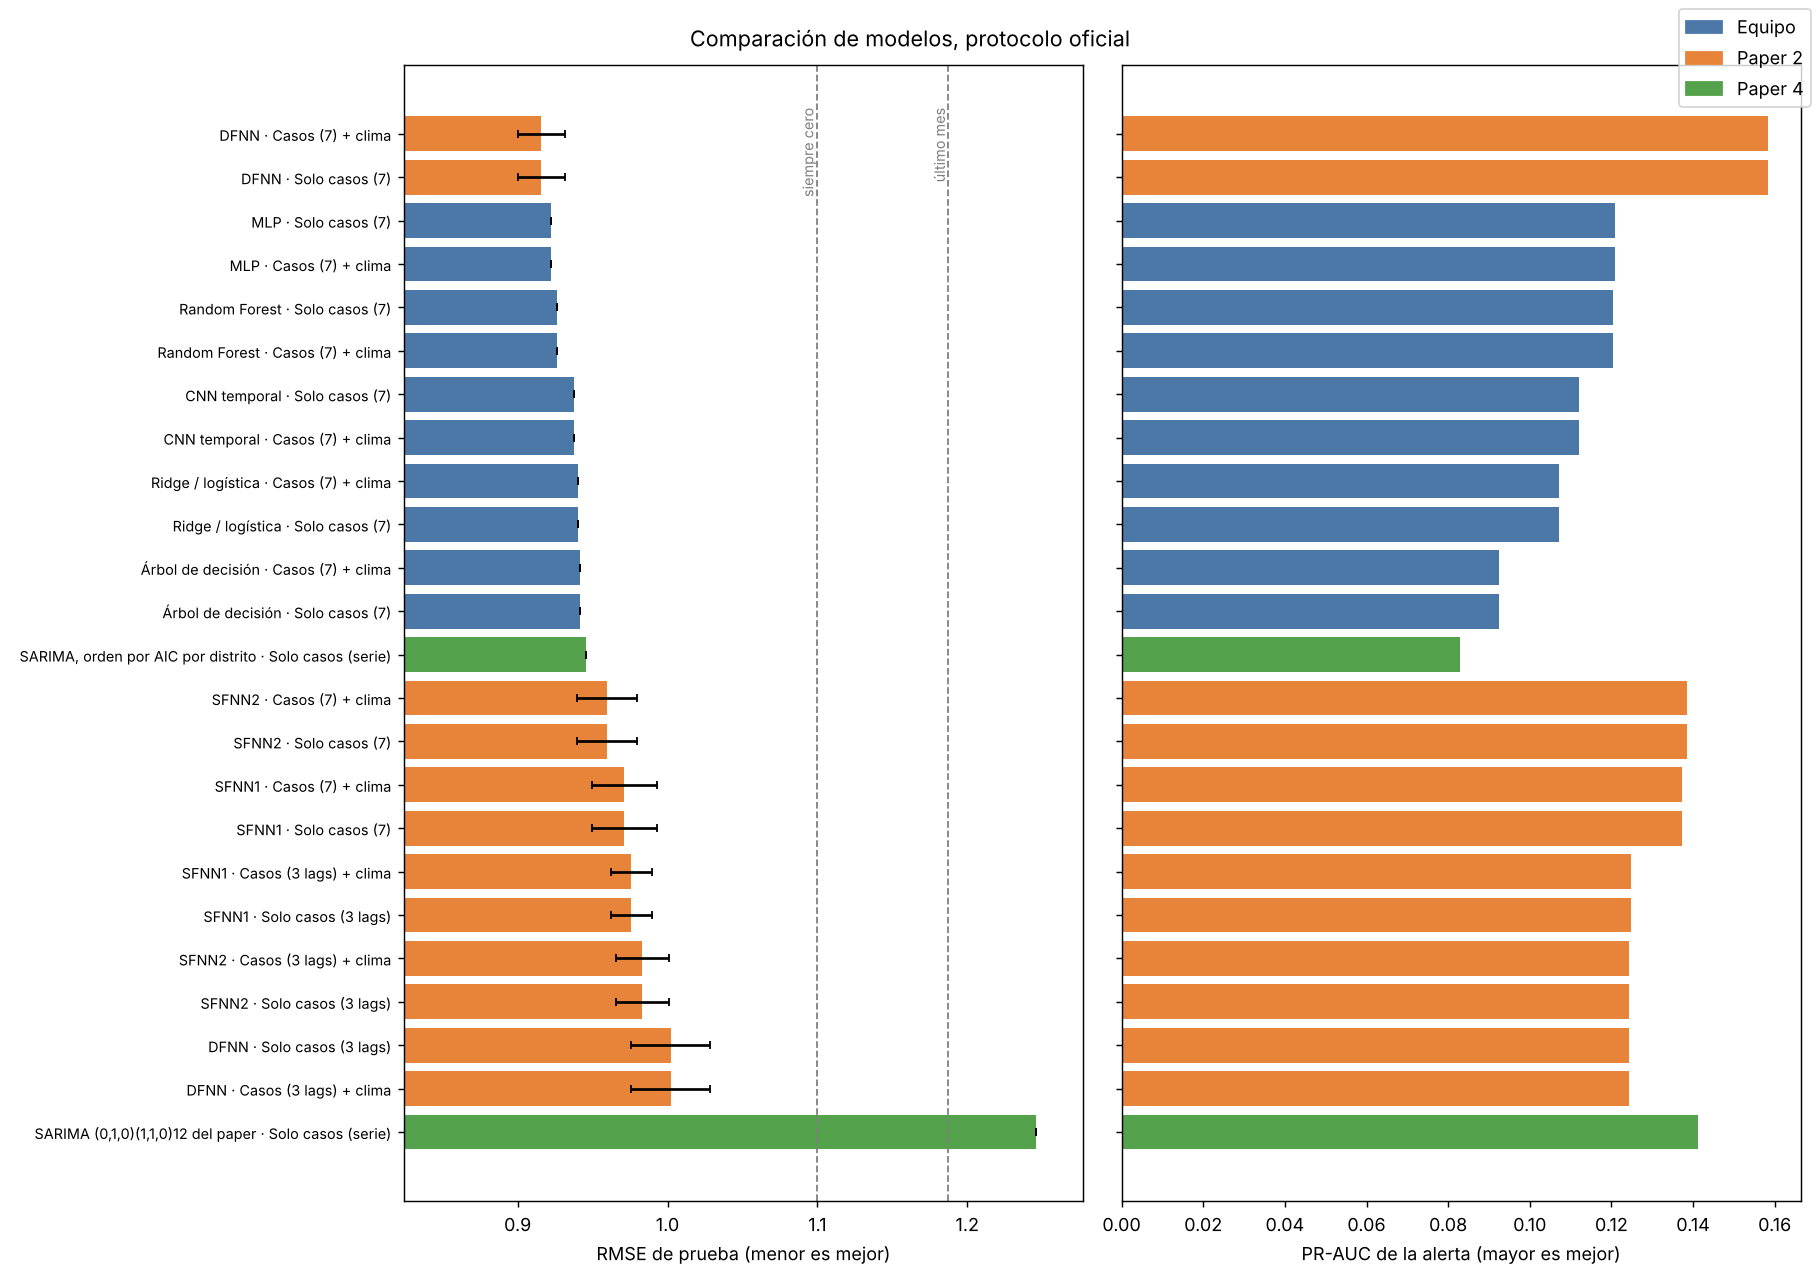

In [6]:
display(Image(str(ROOT / "results/comparacion_final/comparacion_oficial.png")))

In [7]:
al = ["origen", "modelo", "entradas", "PR_AUC", "ROC_AUC", "EER", "recall", "precision", "F1", "TP", "FP", "FN", "TN"]
display(oficial[oficial.origen != "Referencia"].sort_values("PR_AUC", ascending=False)[al].round(3).reset_index(drop=True))

,origen,modelo,entradas,PR_AUC,ROC_AUC,EER,recall,precision,F1,TP,FP,FN,TN
0,Paper 2,DFNN,Solo casos (7),0.158,0.796,0.259,0.583,0.095,0.164,70.0,664.0,50.0,3320.0
1,Paper 2,DFNN,Casos (7) + clima,0.158,0.796,0.259,0.583,0.095,0.164,70.0,664.0,50.0,3320.0
2,Paper 4,"SARIMA (0,1,0)(1,1,0)12 del paper",Solo casos (serie),0.141,0.725,0.333,0.417,0.088,0.145,50.0,518.0,70.0,3466.0
3,Paper 2,SFNN2,Solo casos (7),0.138,0.794,0.267,0.558,0.086,0.150,67.0,709.0,53.0,3275.0
4,Paper 2,SFNN2,Casos (7) + clima,0.138,0.794,0.267,0.558,0.086,0.150,67.0,709.0,53.0,3275.0
5,Paper 2,SFNN1,Solo casos (7),0.137,0.771,0.326,0.550,0.088,0.151,66.0,688.0,54.0,3296.0
6,Paper 2,SFNN1,Casos (7) + clima,0.137,0.771,0.326,0.550,0.088,0.151,66.0,688.0,54.0,3296.0
7,Paper 2,SFNN1,Solo casos (3 lags),0.125,0.727,0.316,0.600,0.077,0.137,72.0,858.0,48.0,3126.0
8,Paper 2,SFNN1,Casos (3 lags) + clima,0.125,0.727,0.316,0.600,0.077,0.137,72.0,858.0,48.0,3126.0
9,Paper 2,SFNN2,Casos (3 lags) + clima,0.124,0.726,0.321,0.542,0.079,0.138,65.0,754.0,55.0,3230.0


## 5. Casos mensuales totales: observado vs. SARIMA vs. Random Forest

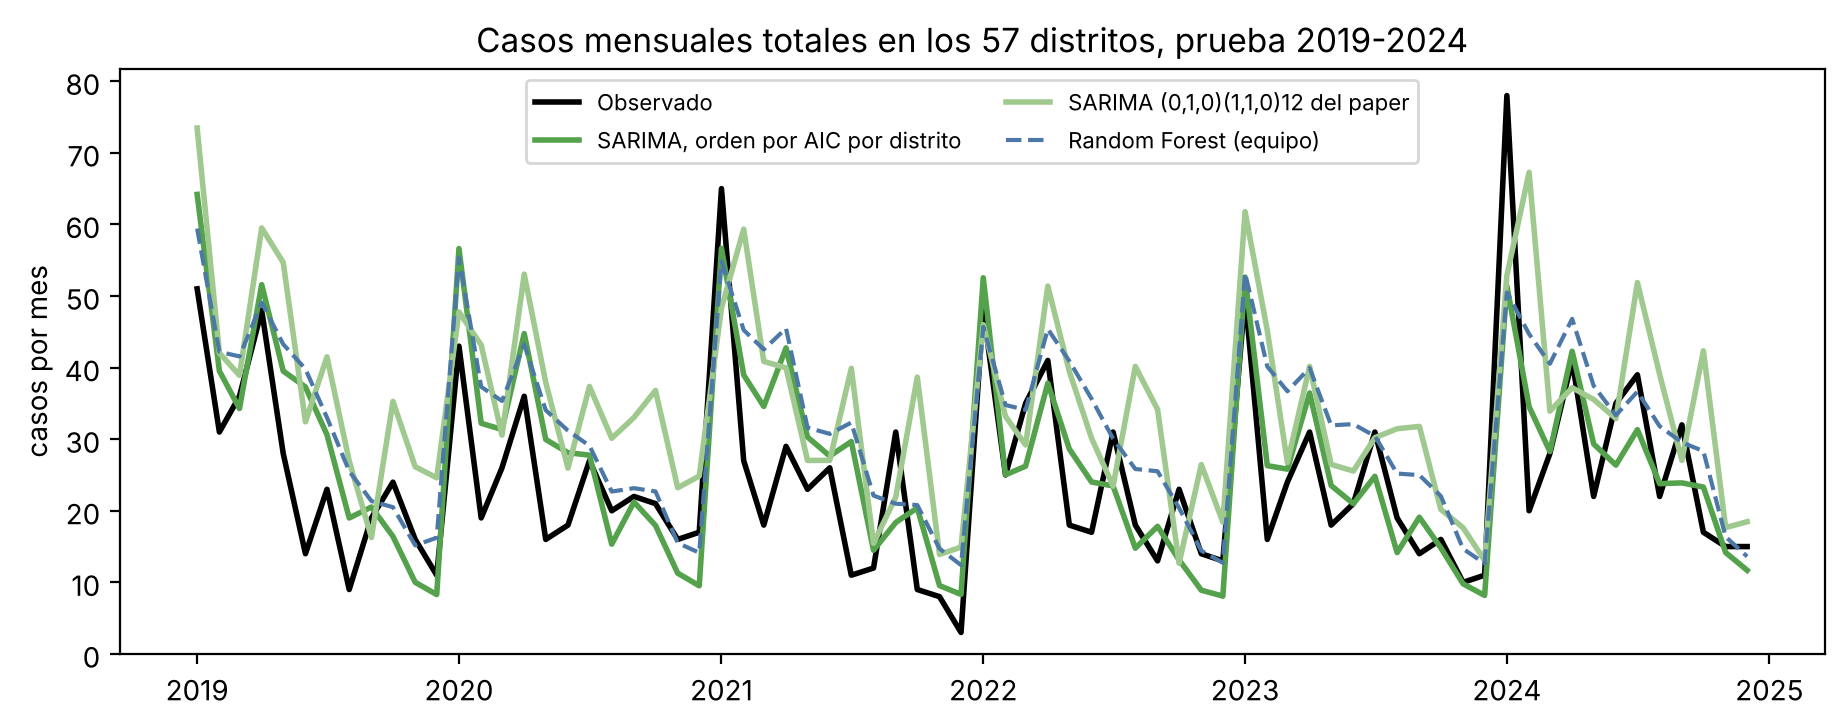

In [8]:
p4pred = pd.read_csv(ROOT / "results/paper4/predicciones.csv", parse_dates=["fecha_mes"])
team = pd.read_csv(ROOT / "results/experimento_clima/predicciones.csv", parse_dates=["fecha_mes"])
rf = team[(team.protocol == "oficial") & (team.variant == "solo_casos") & (team.family == "random_forest")
          & (team.task == "casos")].groupby("fecha_mes").predicted.sum()
obs = p4pred[p4pred.modelo == "SARIMA_AIC"].groupby("fecha_mes").casos_observados.sum()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(obs.index, obs.values, color="black", lw=2, label="Observado")
for name, color in (("SARIMA_AIC", "#54a24b"), ("SARIMA_paper", "#a0c98f")):
    s = p4pred[p4pred.modelo == name].groupby("fecha_mes").casos_predichos.sum()
    ax.plot(s.index, s.values, color=color, lw=2, label=cf.P4_NAMES[name])
ax.plot(rf.index, rf.values, color="#4c78a8", lw=1.5, ls="--", label="Random Forest (equipo)")
ax.set_ylabel("casos por mes"); ax.set_ylim(0, None); ax.legend(ncol=2, fontsize=8)
ax.set_title("Casos mensuales totales en los 57 distritos, prueba 2019-2024")
plt.show()

## Conclusiones

- **SARIMA con orden por AIC** (procedimiento del paper aplicado a cada distrito): RMSE de prueba 0,946, cerca del
  árbol de decisión (0,941) y por detrás de Random Forest (0,926), MLP (0,922) y DFNN (0,916). Tiene el **menor MAE
  de todos los modelos (0,556)**: al no regresar hacia la media de todos los distritos, acierta mejor los muchos meses
  con 0–1 casos. El 86 % de los distritos deja residuos de ruido blanco (Ljung-Box).
- **SARIMA(0,1,0)(1,1,0)₁₂ del paper:** RMSE 1,246, peor que predecir siempre cero (1,100). La doble diferenciación
  que funcionó para la serie provincial de Errachidia amplifica el ruido de series distritales pequeñas. Aun así,
  como puntaje de alerta obtiene la PR-AUC más alta entre los modelos de solo casos del equipo y del paper 4 (0,141).
- **Conclusión:** un modelo estadístico clásico por distrito compite en MAE con los modelos de aprendizaje
  automático, pero en RMSE (los meses con más casos) ganan los modelos no lineales que aprenden de todos los
  distritos a la vez. El orden del paper no se traslada a otra escala geográfica: hay que volver a elegirlo con AIC.

Análisis completo: `docs/ANALISIS_PAPER4.md`.